## Setting up

In [1]:
from src.helpers import setup_env

setup_env()

GPU available
Dataset already downloaded. If you need re-download, please delete the directory landmark_images


Computing std: 100%|███████████████████████| 6246/6246 [00:59<00:00, 105.77it/s]


## Data

In [4]:
!pytest -vv src/data.py -k data_loaders

============================= test session starts =============================
platform win32 -- Python 3.13.15, pytest-7.1.1, pluggy-1.7.0 -- D:\python-envs\pytorch-gpu\Scripts\python.exe
cachedir: .pytest_cache
rootdir: d:\landmark-classification
plugins: anyio-4.15.1, platformdirs-4.12.4
collecting ... collected 4 items / 1 deselected / 3 selected

src/data.py::test_data_loaders_keys <- ..\backup\development-web\AI core\Deep Learning\Course 3 Convolutional Neural Networks\landmark-classification\src\data.py PASSED [ 33%]
src/data.py::test_data_loaders_output_type <- ..\backup\development-web\AI core\Deep Learning\Course 3 Convolutional Neural Networks\landmark-classification\src\data.py PASSED [ 66%]
src/data.py::test_data_loaders_output_shape <- ..\backup\development-web\AI core\Deep Learning\Course 3 Convolutional Neural Networks\landmark-classification\src\data.py PASSED [100%]

======================= 3 passed, 1 deselected in 5.01s =======================


Question: Describe your chosen procedure for preprocessing the data

- Resizing image to a resolution of 256 pixels, and then cropping it to 224 pixels. (224 is a recommend input size for leveraging Pytorch's pretrained models)
- Using RandAugment to enhance dataset

### Visualize a Batch of Training Data

In [5]:
!pytest -vv src/data.py -k visualize_one_batch

============================= test session starts =============================
platform win32 -- Python 3.13.15, pytest-7.1.1, pluggy-1.7.0 -- D:\python-envs\pytorch-gpu\Scripts\python.exe
cachedir: .pytest_cache
rootdir: d:\landmark-classification
plugins: anyio-4.15.1, platformdirs-4.12.4
collecting ... collected 4 items / 3 deselected / 1 selected

src/data.py::test_visualize_one_batch <- ..\backup\development-web\AI core\Deep Learning\Course 3 Convolutional Neural Networks\landmark-classification\src\data.py PASSED [100%]

============================== warnings summary ===============================
src/data.py::test_visualize_one_batch
src/data.py::test_visualize_one_batch
  D:\python-envs\pytorch-gpu\Lib\site-packages\matplotlib\cbook.py:713: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/nump

Reusing cached mean and std
Dataset mean: tensor([0.4638, 0.4725, 0.4687]), std: tensor([0.2697, 0.2706, 0.3017])
Reusing cached mean and std


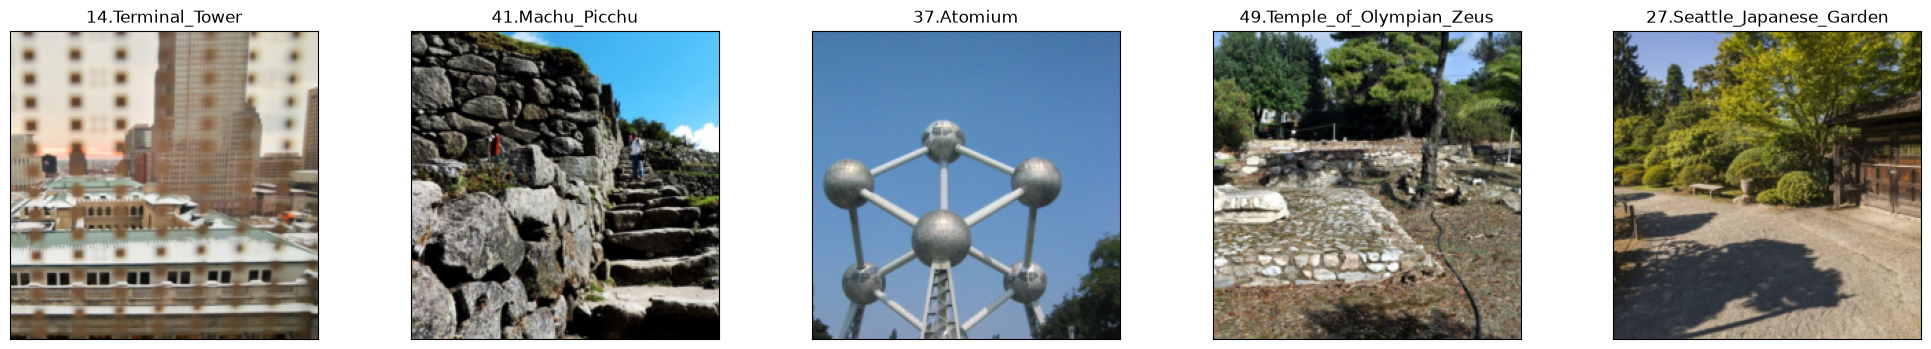

In [1]:
%matplotlib inline
from src.data import visualize_one_batch, get_data_loaders

data_loaders = get_data_loaders(
    batch_size=5,
    valid_size=0.01,
    num_workers=2,
)

visualize_one_batch(data_loaders)

In [ ]:
## Define model

In [1]:
!pytest -vv src/model.py

============================= test session starts =============================
platform win32 -- Python 3.13.15, pytest-7.1.1, pluggy-1.7.0 -- D:\python-envs\pytorch-gpu\Scripts\python.exe
cachedir: .pytest_cache
rootdir: d:\landmark-classification
plugins: anyio-4.15.1, platformdirs-4.12.4
collecting ... collected 1 item

src/model.py::test_model_construction <- ..\backup\development-web\AI core\Deep Learning\Course 3 Convolutional Neural Networks\landmark-classification\src\model.py PASSED [100%]

============================= 1 passed in 58.02s ==============================


Question: Outline the steps you took to get the final CNN architecture and your reasoning at each step

Answer:
- I decided to use 5 convolutional layers so that my model could be sufficiently expressive. The last convolution layer is flattened into a fully connected layer head with two hidden layers to best predict image class.      
- I used dropout layers to reduce my model's tendency to overfitting the training data
- I made my model output a 50-dimensional vector to match with the 50 available landmark classes

## Define loss and optimizer

In [2]:
!pytest -vv src/optimization.py -k get_loss

============================= test session starts =============================
platform win32 -- Python 3.13.15, pytest-7.1.1, pluggy-1.7.0 -- D:\python-envs\pytorch-gpu\Scripts\python.exe
cachedir: .pytest_cache
rootdir: d:\landmark-classification
plugins: anyio-4.15.1, platformdirs-4.12.4
collecting ... collected 7 items / 6 deselected / 1 selected

src/optimization.py::test_get_loss <- ..\backup\development-web\AI core\Deep Learning\Course 3 Convolutional Neural Networks\landmark-classification\src\optimization.py PASSED [100%]

======================= 1 passed, 6 deselected in 2.67s =======================


In [3]:
!pytest -vv src/optimization.py -k get_optimizer

============================= test session starts =============================
platform win32 -- Python 3.13.15, pytest-7.1.1, pluggy-1.7.0 -- D:\python-envs\pytorch-gpu\Scripts\python.exe
cachedir: .pytest_cache
rootdir: d:\landmark-classification
plugins: anyio-4.15.1, platformdirs-4.12.4
collecting ... collected 7 items / 1 deselected / 6 selected

src/optimization.py::test_get_optimizer_type <- ..\backup\development-web\AI core\Deep Learning\Course 3 Convolutional Neural Networks\landmark-classification\src\optimization.py PASSED [ 16%]
src/optimization.py::test_get_optimizer_is_linked_with_model <- ..\backup\development-web\AI core\Deep Learning\Course 3 Convolutional Neural Networks\landmark-classification\src\optimization.py PASSED [ 33%]
src/optimization.py::test_get_optimizer_returns_adam <- ..\backup\development-web\AI core\Deep Learning\Course 3 Convolutional Neural Networks\landmark-classification\src\optimization.py PASSED [ 50%]
src/optimization.py::test_get_optimizer_se

## Train and Validate the Model

In [4]:
!pytest -vv src/train.py -k train_one_epoch

============================= test session starts =============================
platform win32 -- Python 3.13.15, pytest-7.1.1, pluggy-1.7.0 -- D:\python-envs\pytorch-gpu\Scripts\python.exe
cachedir: .pytest_cache
rootdir: d:\landmark-classification
plugins: anyio-4.15.1, platformdirs-4.12.4
collecting ... collected 4 items / 3 deselected / 1 selected

src/train.py::test_train_one_epoch PASSED                                [100%]

============================== warnings summary ===============================
..\python-envs\pytorch-gpu\Lib\site-packages\_pytest\assertion\rewrite.py:962
..\python-envs\pytorch-gpu\Lib\site-packages\_pytest\assertion\rewrite.py:962
..\python-envs\pytorch-gpu\Lib\site-packages\_pytest\assertion\rewrite.py:962
..\python-envs\pytorch-gpu\Lib\site-packages\_pytest\assertion\rewrite.py:962
..\python-envs\pytorch-gpu\Lib\site-packages\_pytest\assertion\rewrite.py:962
..\python-envs\pytorch-gpu\Lib\site-packages\_pytest\assertion\rewrite.py:962
..\python-envs\p

In [5]:
!pytest -vv src/train.py -k valid_one_epoch

============================= test session starts =============================
platform win32 -- Python 3.13.15, pytest-7.1.1, pluggy-1.7.0 -- D:\python-envs\pytorch-gpu\Scripts\python.exe
cachedir: .pytest_cache
rootdir: d:\landmark-classification
plugins: anyio-4.15.1, platformdirs-4.12.4
collecting ... collected 4 items / 3 deselected / 1 selected

src/train.py::test_valid_one_epoch PASSED                                [100%]

============================== warnings summary ===============================
src/train.py::test_valid_one_epoch
src/train.py::test_valid_one_epoch
  D:\python-envs\pytorch-gpu\Lib\site-packages\tqdm\std.py:468: DeprecationWarning: datetime.datetime.utcfromtimestamp() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.fromtimestamp(timestamp, datetime.UTC).
    if rate and total else datetime.utcfromtimestamp(0))

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-

In [6]:
!pytest -vv src/train.py -k optimize

============================= test session starts =============================
platform win32 -- Python 3.13.15, pytest-7.1.1, pluggy-1.7.0 -- D:\python-envs\pytorch-gpu\Scripts\python.exe
cachedir: .pytest_cache
rootdir: d:\landmark-classification
plugins: anyio-4.15.1, platformdirs-4.12.4
collecting ... collected 4 items / 3 deselected / 1 selected

src/train.py::test_optimize PASSED                                       [100%]

============================== warnings summary ===============================
src/train.py::test_optimize
src/train.py::test_optimize
src/train.py::test_optimize
src/train.py::test_optimize
  D:\python-envs\pytorch-gpu\Lib\site-packages\tqdm\std.py:468: DeprecationWarning: datetime.datetime.utcfromtimestamp() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.fromtimestamp(timestamp, datetime.UTC).
    if rate and total else datetime.utcfromtimestamp(0))

-- Docs: https:/

In [1]:
!pytest -vv src/train.py -k one_epoch_test

============================= test session starts =============================
platform win32 -- Python 3.13.15, pytest-7.1.1, pluggy-1.7.0 -- D:\python-envs\pytorch-gpu\Scripts\python.exe
cachedir: .pytest_cache
rootdir: d:\landmark-classification
plugins: anyio-4.15.1, platformdirs-4.12.4
collecting ... collected 4 items / 3 deselected / 1 selected

src/train.py::test_one_epoch_test <- ..\backup\development-web\AI core\Deep Learning\Course 3 Convolutional Neural Networks\landmark-classification\src\train.py PASSED [100%]

============================== warnings summary ===============================
src/train.py::test_one_epoch_test
  D:\python-envs\pytorch-gpu\Lib\site-packages\tqdm\std.py:468: DeprecationWarning: datetime.datetime.utcfromtimestamp() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.fromtimestamp(timestamp, datetime.UTC).
    if rate and total else datetime.utcfromtimestamp(0))


## Putting everything together

In [2]:
batch_size = 64        # size of the minibatch for stochastic gradient descent (or Adam)
valid_size = 0.2       # fraction of the training data to reserve for validation
num_epochs = 50        # number of epochs for training
num_classes = 50       # number of classes. Do not change this
dropout = 0.4          # dropout for our model
learning_rate = 0.001  # Learning rate for SGD (or Adam)
opt = 'sgd'            # optimizer. 'sgd' or 'adam'
weight_decay = 0.0     # regularization. Increase this to combat overfitting

In [3]:
from src.data import get_data_loaders
from src.train import optimize
from src.optimization import get_optimizer, get_loss
from src.model import MyModel

data_loaders = get_data_loaders(
    batch_size=batch_size, 
    valid_size=valid_size,
)

model = MyModel(num_classes=num_classes, dropout=dropout)

optimizer = get_optimizer(
    model=model,
    optimizer=opt,
    learning_rate=learning_rate,
    weight_decay=weight_decay
)

loss = get_loss()

optimize(
    data_loaders,
    model,
    optimizer,
    loss,
    n_epochs=num_epochs,
    save_path="checkpoints/best_val_loss.pt",
    interactive_tracking=True,
)

Reusing cached mean and std
Dataset mean: tensor([0.4638, 0.4725, 0.4687]), std: tensor([0.2697, 0.2706, 0.3017])


Training:   0%|                                          | 0/63 [00:02<?, ?it/s]


OutOfMemoryError: CUDA out of memory. Tried to allocate 98.00 MiB. GPU 0 has a total capacity of 4.00 GiB of which 1.53 GiB is free. Of the allocated memory 1.62 GiB is allocated by PyTorch, and 64.12 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

## Testing against the test set

In [ ]:
from src.train import one_epoch_test